# GOAT at high correlation: test every singleton seed

**Question:** on one fixed graph pair, which of Graph A's 600 vertices work as the sole seed?

Choose the **ds** kernel and **Run All**. The default is the saved **ER, target mean degree 12, rho = 0.70** pair (12/20 singleton successes in calibration). Change `PAIR_NAME` to `er_degree16` for the original high-rho pair (8/20). This uses no pre-existing seed set: each vertex is tested alone with its correct correspondence.

The main experiment is 600 GOAT calls, plus one no-seed control and 24 small repeatability calls by default. Progress and estimated remaining time print every 25 vertices. Results are checkpointed atomically after every call; rerunning resumes without repeating completed calls. This is a separate experiment from choosing an additional seed for an existing seed set.

**Interpretation:** the complete map is exact for the saved pair, primary solver seed and numerical settings. It is not an estimate across graph pairs or B realizations. Repeatability checks assess a small sample only. Success means at least 90% accuracy on the **599 unseeded vertices**. Existing calibration outcomes are not used to fit or select features.


In [1]:
from pathlib import Path
import os
import sys
import tempfile
import time
import hashlib
import json
import importlib.metadata

os.environ.setdefault('NUMBA_CACHE_DIR', str(Path(tempfile.gettempdir()) / 'sgm_numba_cache'))
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'sgm_matplotlib_cache'))

# Works when launched from the repository root or this notebook's directory.
ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / 'experiment_common' / 'sgm.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from within the Seeded-Graph-Matching repository.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import shortest_path
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

from experiment_common.sgm import run_sgm_once
from experiment_common.graph_checks import check_graph_pair
from experiment_common.provenance import collect_environment, thread_limit, write_json

PAIR_NAME = 'er_degree12'  # 'er_degree12' or 'er_degree16'
PRIMARY_SOLVER_SEED = 20261020
BLAS_THREADS = 4
SUCCESS_THRESHOLD = 0.90
MAX_VERTICES = None       # None = all 600; set to 5 for a quick trial, then back to None to resume
RUN_NO_SEED_CONTROL = True
N_STABILITY_VERTICES = 12  # fixed random subset, chosen without outcomes
STABILITY_SOLVER_SEEDS = (20261021, 20261022)
OUTPUT_ROOT = ROOT / 'one_seed_marginal_problem' / 'data' / 'goat_high_rho_singletons'

PAIR_FILES = {
    'er_degree12': ROOT / 'research_notes' / 'goat_high_rho_density_calibration_2026-10-20' /
                   'degree_12' / 'pairs' / 'sparse_er' / 'sparse_er_problem.npz',
    'er_degree16': ROOT / 'research_notes' / 'goat_high_rho_calibration_2026-10-20' /
                   'pairs' / 'sparse_er' / 'sparse_er_problem.npz',
}
SOLVER_SETTINGS = dict(max_iter=100, tol=0.01, transport=True,
                       transport_regularizer=100, transport_tol=0.05, transport_max_iter=5000)
RANDOM_STATE = 2026
print('Pair:', PAIR_NAME, '| output:', OUTPUT_ROOT / PAIR_NAME)


Pair: er_degree12 | output: /Users/langsong/Desktop/Seeded-Graph-Matching/one_seed_marginal_problem/data/goat_high_rho_singletons/er_degree12


## 1. Load the exact calibrated pair and protect saved results

The saved matrices and true permutation are used directly. Graph structure, solver settings, source hashes and package versions are recorded. A changed experiment configuration requires a new output directory. `MAX_VERTICES` and the number of stability checks can be increased on resume.


In [2]:
def digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

pair_path = PAIR_FILES[PAIR_NAME]
if not pair_path.is_file():
    raise FileNotFoundError(f'Missing saved calibration pair: {pair_path}')
source_metadata = json.loads(pair_path.with_suffix('.metadata.json').read_text())
with np.load(pair_path, allow_pickle=False) as saved:
    A = saved['adjacency_graph1'].copy()
    B = saved['adjacency_graph2'].copy()
    truth = saved['true_permutation'].astype(int).copy()
n = len(A)
assert A.shape == B.shape == (n, n) and n == 600
assert np.array_equal(np.sort(truth), np.arange(n))
assert np.allclose(A, A.T) and np.allclose(B, B.T)
structure = check_graph_pair(A, B)
if not structure['passes']:
    raise ValueError(f'The saved pair failed structural checks: {structure}')
assert source_metadata['config']['rho'] == 0.70
assert source_metadata.get('regularizer', 100) == SOLVER_SETTINGS['transport_regularizer']
assert len(set(STABILITY_SOLVER_SEEDS)) == len(STABILITY_SOLVER_SEEDS)
assert PRIMARY_SOLVER_SEED not in STABILITY_SOLVER_SEEDS
if MAX_VERTICES is not None and not 1 <= MAX_VERTICES <= n:
    raise ValueError('MAX_VERTICES must be None or an integer between 1 and 600.')
if not 0 <= N_STABILITY_VERTICES <= n:
    raise ValueError('N_STABILITY_VERTICES must be between 0 and 600.')

output_dir = OUTPUT_ROOT / PAIR_NAME
output_dir.mkdir(parents=True, exist_ok=True)
manifest = {
    'experiment_version': 1, 'pair_name': PAIR_NAME,
    'pair_sha256': digest(pair_path),
    'pair_metadata_sha256': digest(pair_path.with_suffix('.metadata.json')),
    'sgm_wrapper_sha256': digest(ROOT / 'experiment_common' / 'sgm.py'),
    'graph_pair_seed': source_metadata['graph_pair_seed'],
    'primary_solver_seed': PRIMARY_SOLVER_SEED, 'success_threshold': SUCCESS_THRESHOLD,
    'solver_settings': SOLVER_SETTINGS, 'blas_threads': BLAS_THREADS,
    'stability_vertex_stream': RANDOM_STATE,
    'package_versions': {p: importlib.metadata.version(p)
                         for p in ['numpy', 'scipy', 'graspologic', 'scikit-learn']},
}
manifest_path = output_dir / 'settings.json'
if manifest_path.exists():
    if json.loads(manifest_path.read_text()) != manifest:
        raise ValueError('Saved experiment settings differ. Use a new OUTPUT_ROOT to preserve existing results.')
else:
    write_json(manifest_path, manifest)
    write_json(output_dir / 'environment.json', collect_environment(BLAS_THREADS))

runs_path = output_dir / 'runs.csv'
records = pd.read_csv(runs_path).to_dict('records') if runs_path.exists() else []
if records:
    keys = [(int(r['vertex']), int(r['solver_seed'])) for r in records]
    if len(keys) != len(set(keys)):
        raise ValueError('Duplicate saved runs: inspect runs.csv before resuming.')
    if any(v < -1 or v >= n for v, _ in keys):
        raise ValueError('Invalid vertex in saved results.')

summary = pd.DataFrame([{
    'vertices': n, 'rho': source_metadata['config']['rho'],
    'mean_degree_A': A.sum(axis=1).mean(), 'mean_degree_B': B.sum(axis=1).mean(),
    'primary_singleton_runs_saved': sum(int(r['vertex']) >= 0 and
                                      int(r['solver_seed']) == PRIMARY_SOLVER_SEED for r in records),
}])
display(summary)


,vertices,rho,mean_degree_A,mean_degree_B,primary_singleton_runs_saved
0,600,0.7,11.806667,11.886667,0


## 2. Run all singleton seeds (resumable)

Every vertex uses the same primary solver seed and numerical settings. Graph B and the truth are used by the matcher to supply the one queried correspondence and to measure accuracy; the features below use Graph A only. `vertex = -1` denotes the empty-seed control.

An interruption retains all completed calls. Re-run this cell to continue. A five-vertex trial is intentionally partial; the status and plots will say so.


In [3]:
def save_records():
    frame = pd.DataFrame(records)
    temporary = runs_path.with_suffix('.csv.tmp')
    frame.to_csv(temporary, index=False)
    temporary.replace(runs_path)


def evaluate_vertex(vertex, solver_seed):
    key = (int(vertex), int(solver_seed))
    existing = next((r for r in records if (int(r['vertex']), int(r['solver_seed'])) == key), None)
    if existing is not None:
        return existing
    seeds = np.array([] if vertex == -1 else [vertex], dtype=int)
    with thread_limit(BLAS_THREADS):
        result = run_sgm_once(A, B, truth, seeds, int(solver_seed),
                              **SOLVER_SETTINGS, return_diagnostics=True)
    accuracy = float(result['final_unseeded_accuracy'])
    if not np.isfinite(accuracy) or not 0 <= accuracy <= 1:
        raise ValueError(f'Invalid accuracy for vertex {vertex}: {accuracy}')
    # Accuracy must be an integer number of correct unseeded correspondences.
    count = accuracy * (n - len(seeds))
    if not np.isclose(count, round(count)):
        raise ValueError('Accuracy denominator does not match the seed budget.')
    row = {'vertex': int(vertex), 'solver_seed': int(solver_seed),
           'success': bool(accuracy >= SUCCESS_THRESHOLD), **result}
    records.append(row)
    save_records()
    return row


def primary_results():
    frame = pd.DataFrame(records)
    if frame.empty:
        return frame
    return (frame[(frame['vertex'] >= 0) & (frame['solver_seed'] == PRIMARY_SOLVER_SEED)]
            .sort_values('vertex').reset_index(drop=True))

if RUN_NO_SEED_CONTROL:
    control = evaluate_vertex(-1, PRIMARY_SOLVER_SEED)
    print(f"No-seed accuracy: {control['final_unseeded_accuracy']:.3f}", flush=True)
vertices_to_run = np.arange(n if MAX_VERTICES is None else MAX_VERTICES)
already = {int(r['vertex']) for r in records if int(r['solver_seed']) == PRIMARY_SOLVER_SEED}
pending = [int(v) for v in vertices_to_run if v not in already]
print(f'{len(pending)} new calls; {len(vertices_to_run)} vertices requested.', flush=True)
started = time.perf_counter()
for j, vertex in enumerate(pending, 1):
    evaluate_vertex(vertex, PRIMARY_SOLVER_SEED)
    if j == 1 or j % 25 == 0 or j == len(pending):
        elapsed = time.perf_counter() - started
        eta = elapsed / j * (len(pending) - j)
        print(f'{j}/{len(pending)} new calls; elapsed {elapsed/60:.1f} min; '
              f'estimated remaining {eta/60:.1f} min', flush=True)
primary = primary_results()
write_json(output_dir / 'status.json', {
    'primary_vertices_completed': len(primary), 'total_vertices': n,
    'primary_map_complete': len(primary) == n,
    'successes': int(primary['success'].astype(str).str.lower().isin(['true', '1']).sum()),
})
print(f'Saved {len(primary)}/{n} singleton vertices to {runs_path}')


No-seed accuracy: 0.047
600 new calls; 600 vertices requested.
1/600 new calls; elapsed 0.1 min; estimated remaining 48.1 min
25/600 new calls; elapsed 1.9 min; estimated remaining 44.1 min
50/600 new calls; elapsed 3.5 min; estimated remaining 38.0 min
75/600 new calls; elapsed 5.2 min; estimated remaining 36.4 min
100/600 new calls; elapsed 6.9 min; estimated remaining 34.3 min
125/600 new calls; elapsed 8.1 min; estimated remaining 30.9 min
150/600 new calls; elapsed 9.7 min; estimated remaining 29.1 min
175/600 new calls; elapsed 11.5 min; estimated remaining 27.9 min
200/600 new calls; elapsed 13.2 min; estimated remaining 26.5 min
225/600 new calls; elapsed 15.0 min; estimated remaining 24.9 min
250/600 new calls; elapsed 16.6 min; estimated remaining 23.3 min
275/600 new calls; elapsed 18.3 min; estimated remaining 21.6 min
300/600 new calls; elapsed 19.8 min; estimated remaining 19.8 min
325/600 new calls; elapsed 21.2 min; estimated remaining 17.9 min
350/600 new calls; elapse

## 3. Small solver-repeatability check

This fixed random subset is selected without seeing outcomes. Each available vertex is rerun with two additional solver seeds. Disagreement means the primary census should be interpreted as one numerical realization, and more repeats may be needed. Agreement on this subset does not prove all 600 labels are invariant. These runs are kept separate from the primary map.


In [4]:
stability_vertices = np.random.default_rng(RANDOM_STATE).permutation(n)[:N_STABILITY_VERTICES]
available = set(primary_results()['vertex'].astype(int))
for vertex in stability_vertices:
    if int(vertex) in available:
        for solver_seed in STABILITY_SOLVER_SEEDS:
            evaluate_vertex(int(vertex), solver_seed)

all_runs = pd.DataFrame(records)
checked = all_runs[(all_runs['vertex'].isin(stability_vertices)) &
                   (all_runs['solver_seed'].isin([PRIMARY_SOLVER_SEED, *STABILITY_SOLVER_SEEDS]))]
repeatability = checked.groupby('vertex').agg(
    solver_runs=('solver_seed', 'nunique'),
    min_accuracy=('final_unseeded_accuracy', 'min'),
    max_accuracy=('final_unseeded_accuracy', 'max'),
)
repeatability['label_changed'] = ((repeatability['min_accuracy'] < SUCCESS_THRESHOLD) &
                                  (repeatability['max_accuracy'] >= SUCCESS_THRESHOLD))
repeatability.to_csv(output_dir / 'repeatability.csv')
display(repeatability)
print(f"{int(repeatability['label_changed'].sum())} label changes among "
      f"{int((repeatability['solver_runs'] > 1).sum())} vertices with repeated calls.")


,solver_runs,min_accuracy,max_accuracy,label_changed
vertex,,,,
51,3,0.193656,0.193656,False
70,3,0.023372,0.023372,False
80,3,1.000000,1.000000,False
156,3,1.000000,1.000000,False
171,3,1.000000,1.000000,False
229,3,1.000000,1.000000,False
237,3,0.135225,0.135225,False
316,3,0.045075,0.045075,False
340,3,0.046745,0.046745,False


0 label changes among 12 vertices with repeated calls.


## 4. Features for a single anchor vertex

Pair mass, witness overlap and seed-pair Jaccard collapse to zero or are undefined for a singleton. We instead examine **degree, harmonic centrality, two-hop reach, mean neighbor degree, clustering and eccentricity**, all from Graph A. We also save three-hop reach and mean distance for exploration.

The `truth_*` column below is a separate diagnostic: the fraction of this vertex's A edges retained in B under the true matching. It uses hidden information and must never be included in a pre-query selector.


In [5]:
G = nx.from_numpy_array(A)
distances = shortest_path(csr_matrix(A), directed=False, unweighted=True)
reachable = (distances > 0) & np.isfinite(distances)
reciprocal = np.divide(1.0, distances, out=np.zeros_like(distances), where=reachable)
degree = A.sum(axis=1).astype(int)
neighbor_degree = nx.average_neighbor_degree(G)
clustering = nx.clustering(G)
aligned_B = B[np.ix_(truth, truth)]
retained = ((A > 0) & (aligned_B > 0)).sum(axis=1)
features = pd.DataFrame({
    'vertex': np.arange(n),
    'degree': degree,
    'harmonic': reciprocal.sum(axis=1),
    'two_hop_reach': ((distances > 0) & (distances <= 2)).sum(axis=1),
    'three_hop_reach': ((distances > 0) & (distances <= 3)).sum(axis=1),
    'mean_neighbor_degree': [neighbor_degree[v] for v in range(n)],
    'clustering': [clustering[v] for v in range(n)],
    'eccentricity': distances.max(axis=1),
    'mean_distance': distances.sum(axis=1) / (n - 1),
    'truth_retained_edge_fraction': np.divide(retained, degree, out=np.zeros(n), where=degree > 0),
})
primary = primary_results().copy()
primary['success'] = primary['final_unseeded_accuracy'] >= SUCCESS_THRESHOLD
data = features.merge(primary, on='vertex', how='inner', validate='one_to_one')
features.to_csv(output_dir / 'vertex_features.csv', index=False)
data.to_csv(output_dir / 'singleton_map.csv', index=False)
FEATURES = ['degree', 'harmonic', 'two_hop_reach', 'mean_neighbor_degree', 'clustering', 'eccentricity']
complete = len(data) == n
print(('COMPLETE CENSUS' if complete else 'PARTIAL RUN') + f': {len(data)}/{n} vertices.')
print(f"Successful singleton seeds: {int(data['success'].sum())}/{len(data)} "
      f"({data['success'].mean():.1%}); mean unseeded accuracy: {data['final_unseeded_accuracy'].mean():.3f}")
print('These proportions are conditional on this pair; no binomial sampling interval is attached to a full census.')
display(data[['sgm_runtime_seconds', 'sgm_n_iter', 'sgm_warning_count']].describe().round(3))
print('Nonconverged primary runs:', int((~data['sgm_converged'].astype(str).str.lower().isin(['true', '1'])).sum()))
display(data.sort_values(['final_unseeded_accuracy', 'vertex'], ascending=[False, True])
        [['vertex', 'success', 'final_unseeded_accuracy', *FEATURES]].head(20))


COMPLETE CENSUS: 600/600 vertices.
Successful singleton seeds: 293/600 (48.8%); mean unseeded accuracy: 0.522
These proportions are conditional on this pair; no binomial sampling interval is attached to a full census.


,sgm_runtime_seconds,sgm_n_iter,sgm_warning_count
count,600.000,600.000,600.0
mean,3.241,35.812,0.0
std,2.298,22.336,0.0
min,0.199,3.000,0.0
25%,1.317,14.750,0.0
50%,2.527,34.000,0.0
75%,4.857,55.000,0.0
max,11.332,97.000,0.0


Nonconverged primary runs: 0


,vertex,success,final_unseeded_accuracy,degree,harmonic,two_hop_reach,mean_neighbor_degree,clustering,eccentricity
4,4,True,1.0,14,229.583333,153,13.000000,0.000000,4.0
5,5,True,1.0,15,233.500000,167,13.266667,0.028571,4.0
8,8,True,1.0,12,225.750000,140,13.416667,0.045455,4.0
9,9,True,1.0,14,234.166667,176,14.785714,0.032967,4.0
10,10,True,1.0,10,221.416667,123,13.700000,0.000000,4.0
12,12,True,1.0,6,209.666667,89,15.500000,0.000000,4.0
14,14,True,1.0,20,245.750000,221,13.700000,0.015789,4.0
18,18,True,1.0,14,227.750000,145,11.928571,0.010989,4.0
20,20,True,1.0,19,240.583333,194,12.105263,0.017544,4.0
22,22,True,1.0,9,218.166667,116,14.666667,0.083333,4.0


## 5. Inspect the map and feature associations

Vertex numbers are identifiers, not a meaningful spatial ordering. The degree/harmonic plot and feature bins show structure more clearly. All plots are exploratory within this fixed pair.


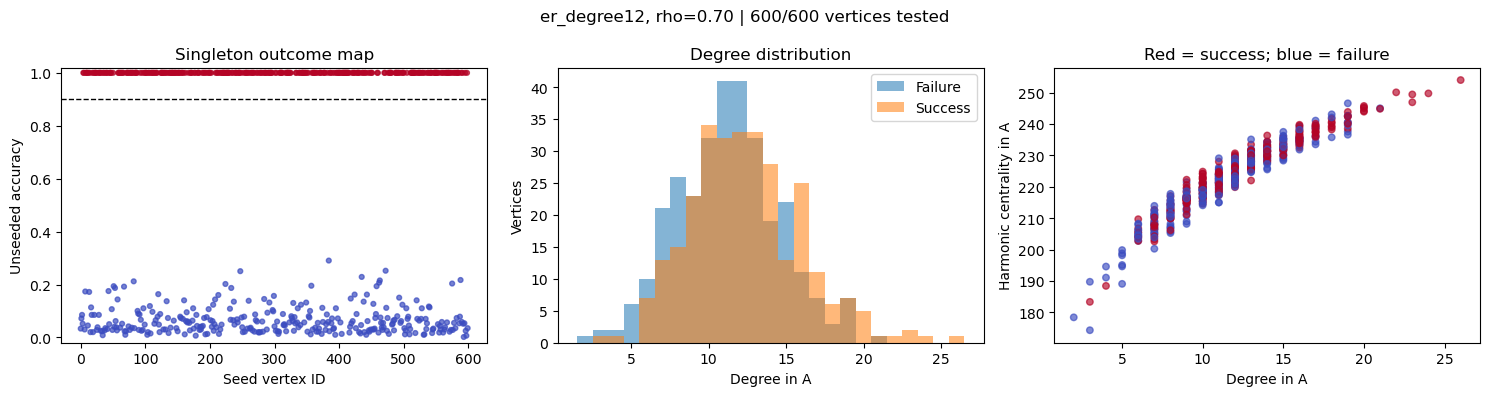

,Spearman with accuracy,AUC higher value = success,mean among failures,mean among successes,usable before query
feature,,,,,
degree,0.167,0.586,11.225,12.416,True
harmonic,0.185,0.599,221.443,225.481,True
two_hop_reach,0.188,0.601,126.906,140.683,True
mean_neighbor_degree,0.067,0.544,12.763,12.963,True
clustering,0.046,0.540,0.021,0.023,True
eccentricity,-0.076,0.491,4.036,4.017,True
truth_retained_edge_fraction,0.323,0.663,0.666,0.747,False


AUC below 0.5 means smaller feature values tend to accompany success. This table is descriptive, not held-out validation.


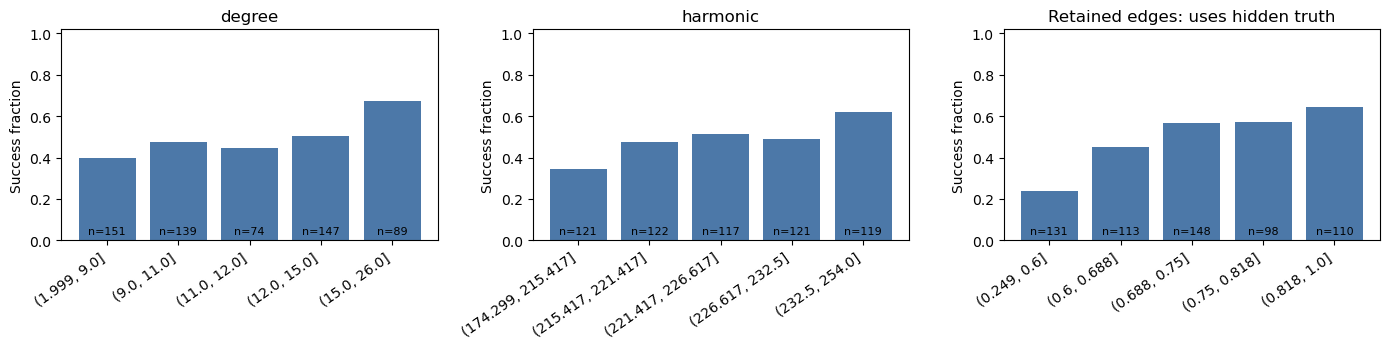

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(data['vertex'], data['final_unseeded_accuracy'], c=data['success'].astype(int),
                cmap='coolwarm', s=12, alpha=0.7)
axes[0].axhline(SUCCESS_THRESHOLD, color='black', linestyle='--', linewidth=1)
axes[0].set(xlabel='Seed vertex ID', ylabel='Unseeded accuracy', title='Singleton outcome map', ylim=(-0.02, 1.02))
for label, group in data.groupby('success'):
    axes[1].hist(group['degree'], bins=np.arange(degree.min()-.5, degree.max()+1.5),
                 alpha=.55, label='Success' if label else 'Failure')
axes[1].set(xlabel='Degree in A', ylabel='Vertices', title='Degree distribution')
axes[1].legend()
axes[2].scatter(data['degree'], data['harmonic'], c=data['success'].astype(int),
                cmap='coolwarm', s=22, alpha=.65)
axes[2].set(xlabel='Degree in A', ylabel='Harmonic centrality in A', title='Red = success; blue = failure')
fig.suptitle(f'{PAIR_NAME}, rho=0.70 | {len(data)}/{n} vertices tested')
fig.tight_layout()
fig.savefig(output_dir / 'singleton_map.png', dpi=160, bbox_inches='tight')
plt.show()

feature_rows = []
for feature in [*FEATURES, 'truth_retained_edge_fraction']:
    auc = roc_auc_score(data['success'], data[feature]) if data['success'].nunique() == 2 else np.nan
    feature_rows.append({'feature': feature,
                         'Spearman with accuracy': (data[feature].corr(data['final_unseeded_accuracy'], method='spearman')
                                                   if data[feature].nunique() > 1 and data['final_unseeded_accuracy'].nunique() > 1
                                                   else np.nan),
                         'AUC higher value = success': auc,
                         'mean among failures': data.loc[~data['success'], feature].mean(),
                         'mean among successes': data.loc[data['success'], feature].mean(),
                         'usable before query': not feature.startswith('truth_')})
associations = pd.DataFrame(feature_rows).set_index('feature')
associations.to_csv(output_dir / 'feature_associations.csv')
display(associations.round(3))
print('AUC below 0.5 means smaller feature values tend to accompany success. This table is descriptive, not held-out validation.')

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, feature in zip(axes, ['degree', 'harmonic', 'truth_retained_edge_fraction']):
    binned = data.assign(bin=pd.qcut(data[feature], q=5, duplicates='drop'))
    rates = binned.groupby('bin', observed=True).agg(count=('success', 'size'), success=('success', 'mean'))
    if not rates.empty:
        ax.bar(np.arange(len(rates)), rates['success'], color='#4C78A8')
        ax.set_xticks(np.arange(len(rates)), [str(b) for b in rates.index], rotation=35, ha='right')
        for j, count in enumerate(rates['count']): ax.text(j, .03, f'n={count}', ha='center', fontsize=8)
    ax.set(title=feature.replace('_', ' '), ylabel='Success fraction', ylim=(0, 1.02))
axes[2].set_title('Retained edges: uses hidden truth')
fig.tight_layout()
fig.savefig(output_dir / 'feature_bins.png', dpi=160, bbox_inches='tight')
plt.show()


## 6. Can Graph-A features predict which singletons work?

This is a **within-pair exploratory comparison** using out-of-fold predictions. Each vertex is held out when its probability is predicted; scaling is fitted inside each training fold. Five stratified folds compare degree-only logistic regression with the six-feature model. Constant predictors are dropped.

The degree-only model may learn either direction. The hidden retained-edge diagnostic is excluded. Vertices share a graph, so this is not a test of transfer to independent graphs. The original calibration pair was selected for useful class variation; all feature conclusions need fresh-pair replication.


In [7]:
oof = data[['vertex', 'success']].copy()
cv_rows = []
class_counts = data['success'].value_counts()
if len(class_counts) < 2 or class_counts.min() < 2:
    print('Too few successes or failures for cross-validation. Run the complete map or inspect another predefined pair.')
else:
    folds = StratifiedKFold(n_splits=min(5, int(class_counts.min())), shuffle=True, random_state=RANDOM_STATE)
    for name, columns in [('Degree logistic', ['degree']), ('Vertex-feature logistic', FEATURES)]:
        columns = [c for c in columns if data[c].nunique() > 1]
        if not columns:
            continue
        model = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000))
        p = cross_val_predict(model, data[columns], data['success'], cv=folds, method='predict_proba')[:, 1]
        oof[name] = p
        cv_rows.append({'model': name, 'out-of-fold AUC': roc_auc_score(data['success'], p),
                        'predictors': ', '.join(columns), 'vertices': len(data)})
    display(pd.DataFrame(cv_rows).round(3))
    oof.to_csv(output_dir / 'out_of_fold_predictions.csv', index=False)
    print('These scores concern other vertices of the SAME pair, not unseen graph pairs.')


,model,out-of-fold AUC,predictors,vertices
0,Degree logistic,0.580,degree,600
1,Vertex-feature logistic,0.567,"degree, harmonic, two_hop_reach, mean_neighbor...",600


These scores concern other vertices of the SAME pair, not unseen graph pairs.


## 7. A simple selection check and what to do next

For each A-only rule, the table measures success among the top-ranked tested vertices. The full census makes this the exact result of choosing uniformly from that subset on this pair. Ties use a fixed random key. The table does not fit a rule to the observed labels. With a partial run it covers only tested vertices, not all of A.

Next: reproduce the map on predefined fresh pairs, then hold A fixed and draw additional B realizations if the goal is identifying reliably good anchors. Keep all outcomes, including easy and difficult pairs. A singleton study cannot establish which seeds complement one another in a multi-seed set.

**Saved files:** `runs.csv` (all primary/control/repeat calls), `singleton_map.csv`, `vertex_features.csv`, `repeatability.csv`, feature tables, out-of-fold predictions when feasible, plots, settings, environment and completion status. To change pair, switch `PAIR_NAME` and rerun all cells. To rerun with different solver settings, choose a new `OUTPUT_ROOT`.


In [8]:
selection_rows = []
ties = np.random.default_rng(RANDOM_STATE).random(n)
for feature in ['degree', 'harmonic', 'two_hop_reach']:
    ranked = data.assign(tie=ties[data['vertex'].to_numpy(int)]).sort_values([feature, 'tie'], ascending=[False, True])
    for fraction in [.05, .10, .25]:
        count = max(1, int(np.ceil(len(ranked) * fraction)))
        selected = ranked.head(count)
        selection_rows.append({'rule': f'Top {feature}', 'top fraction': fraction,
                               'vertices': count, 'success fraction': selected['success'].mean(),
                               'mean accuracy': selected['final_unseeded_accuracy'].mean(),
                               'success improvement over uniform': selected['success'].mean() - data['success'].mean()})
selection = pd.DataFrame(selection_rows)
selection.to_csv(output_dir / 'selection_check.csv', index=False)
display(selection.round(3))
print('Saved analysis to', output_dir)


,rule,top fraction,vertices,success fraction,mean accuracy,success improvement over uniform
0,Top degree,0.05,30,0.700,0.723,0.212
1,Top degree,0.10,60,0.683,0.704,0.195
2,Top degree,0.25,150,0.580,0.608,0.092
3,Top harmonic,0.05,30,0.733,0.749,0.245
4,Top harmonic,0.10,60,0.717,0.737,0.228
5,Top harmonic,0.25,150,0.613,0.639,0.125
6,Top two_hop_reach,0.05,30,0.767,0.781,0.278
7,Top two_hop_reach,0.10,60,0.717,0.736,0.228
8,Top two_hop_reach,0.25,150,0.620,0.645,0.132


Saved analysis to /Users/langsong/Desktop/Seeded-Graph-Matching/one_seed_marginal_problem/data/goat_high_rho_singletons/er_degree12
